In [68]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from scipy.stats import linregress
import dask
import pandas as pd
import seaborn as sns
import glob
from dask_jobqueue import PBSCluster
from dask.distributed import Client
import matplotlib as mpl
from collections import defaultdict
import glob
import re
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

In [2]:
# Setup your PBSCluster
cluster = PBSCluster(
    cores=1,  # Total number of cores across all processes
    memory='100GB',  # Memory per worker
    processes=10,  # Number of processes per worker (1 process per core)
    queue='casper',  # The type of queue to utilize
    local_directory='/glade/derecho/scratch/adixit/tmp/',  # Use your local directory
    resource_spec='select=1:ncpus=10:mem=100GB',  # Resources per worker
    account='UCOR0105',  # Project ID
    walltime='2:00:00',  # Wall time
    #interface='ib0',  # Interface to use (if needed)
)

cluster.scale(jobs=1)  # This will create 200 workers
client = Client(cluster)

In [4]:
client

<Client: 'tcp://128.117.208.184:41193' processes=10 threads=10, memory=93.10 GiB>

In [36]:
scenarios = ["AAER", "BMB", "EE", "GHG", "xAER"]

In [55]:
def group_files(scenario):
    dir = "/glade/campaign/collections/gdex/data/d651055/CESM2-SF/atm/proc/tseries/day_1/TREFHTMX/"
    files = glob.glob(dir + scenario)
    groups = defaultdict(list)

    for f in files:
        m = re.search(r'CESM2-SF-AAER(?:-SSP370)?\.(\d{3})\.cam', f)
        if m:
            groups[m.group(1)].append(f)

    return {
        member: sorted(fs, key=lambda f: f.split('.')[-2])
        for member, fs in sorted(groups.items())
    }

files = group_files('*AAER*')
ds = [xr.open_mfdataset(files[x],parallel=True)['TREFHTMX'].drop_duplicates(dim='time', keep='last') for x in files]

In [56]:
ds_le = xr.concat(ds,dim='lemem')

In [57]:
df = ds_le.sel(time=slice('1950-01-01','2050-12-31'))
df = df.sel(time=df.time.dt.month.isin([5,6]))
df = df.resample(time='YS').mean()

In [58]:
df = dask.compute(df)[0]

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/client.py:3164: UserWarning: Sending large graph of size 58.55 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


In [60]:
df.to_netcdf('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/cesm2-sf/TREFHTMX.AAER.1950-2050.nc')

In [5]:
def group_files(scenario="*"):
    path = "/glade/campaign/collections/gdex/data/d651056/CESM2-LE/atm/proc/tseries/day_1/TREFHTMX/"
    groups = defaultdict(list)

    for f in glob.glob(path + scenario):
        m = re.search(r'LE2-(\d{4}\.\d{3})\.cam', f)
        if m:
            groups[m.group(1)].append(f)

    return {m: sorted(fs, key=lambda f: f.split(".")[-2])
            for m, fs in sorted(groups.items())}

files = group_files("*")
print(len(files))  # check the number of members found

100


In [6]:
ds = [
    xr.open_mfdataset(files[m], parallel=True)["TREFHTMX"]
      .drop_duplicates(dim="time", keep="last")
    for m in files
]

In [7]:
ds_le = xr.concat(ds,dim='lemem')

In [8]:
df = ds_le.sel(time=slice('1950-01-01','2050-12-31'))
df = df.sel(time=df.time.dt.month.isin([5,6]))
df = df.resample(time='YS').mean()

In [9]:
df = dask.compute(df)[0]

/glade/work/adixit/conda-envs/dask/lib/python3.10/site-packages/distributed/client.py:3164: UserWarning: Sending large graph of size 291.62 MiB.
This may cause some slowdown.
Consider scattering data ahead of time and using futures.
  warnings.warn(


In [11]:
df.to_netcdf('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/cesm2-sf/TREFHTMX.ALL.1950-2050.nc')

In [69]:
scenarios = ["AAER", "BMB", "EE", "GHG", "xAER", "ALL"]

ds ={}

for scr in scenarios:
    ds[scr] = xr.open_dataset('/glade/derecho/scratch/adixit/India_Heatwave/review_comments/cesm2-sf/TREFHTMX.%s.1950-2050.nc' %(scr))


In [74]:
def linear_trend(x, y):
    fit = linregress(x, y)
    trend = fit.intercept + fit.slope * x
    return trend, fit.slope * 10, fit.intercept, fit.pvalue  # trend line, slope per decade, intercept

def linear_trend(x, y, dim='time'):
    def reg(x, y):
        fit = linregress(x, y)
        return fit.intercept + fit.slope*x, fit.slope*10, fit.intercept, fit.pvalue

    x = xr.DataArray(x, dims=[dim], coords={dim: y[dim]})
    return xr.apply_ufunc(
        reg, x, y,
        input_core_dims=[[dim], [dim]],
        output_core_dims=[[dim], [], [], []],
        vectorize=True, dask='parallelized',
        output_dtypes=[float]*4,
        dask_gufunc_kwargs={'allow_rechunk': True}
    )

In [71]:
ds_nci = {}
for scr in scenarios:
    ds_nci[scr] = ds[scr].sel(lat=slice(22,30),lon=slice(75,85))
    ds_nci[scr] = ds_nci[scr].resample(time='YS').mean()
    ds_nci[scr] = ds_nci[scr].mean(dim=['lat','lon'])

In [72]:
linear_trend(yr, da)

(array([38.21117049, 38.19182336, 38.17247624, 38.15312912, 38.133782  ,
        38.11443488, 38.09508776, 38.07574064, 38.05639351, 38.03704639,
        38.01769927, 37.99835215, 37.97900503, 37.95965791, 37.94031079,
        37.92096367, 37.90161654, 37.88226942, 37.8629223 , 37.84357518,
        37.82422806, 37.80488094, 37.78553382, 37.76618669, 37.74683957,
        37.72749245, 37.70814533, 37.68879821, 37.66945109, 37.65010397,
        37.63075685, 37.61140972, 37.5920626 , 37.57271548, 37.55336836,
        37.53402124, 37.51467412, 37.495327  , 37.47597987, 37.45663275,
        37.43728563, 37.41793851, 37.39859139, 37.37924427, 37.35989715,
        37.34055003, 37.3212029 , 37.30185578, 37.28250866, 37.26316154,
        37.24381442, 37.2244673 , 37.20512018, 37.18577305, 37.16642593,
        37.14707881, 37.12773169, 37.10838457, 37.08903745, 37.06969033,
        37.0503432 , 37.03099608, 37.01164896, 36.99230184, 36.97295472,
        36.9536076 , 36.93426048, 36.91491336, 36.8

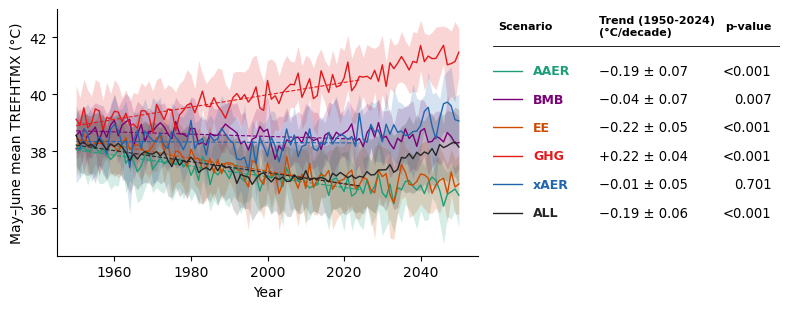

In [96]:
from scipy.stats import linregress

scenarios = ['AAER', 'BMB', 'EE', 'GHG', 'xAER', 'ALL']
cols = {"AAER": "#1b9e77", "BMB": "#7a0177", "EE": "#cc4c02",
        "GHG": "#e31a1c", "xAER": "#2166ac", "ALL": "#252525"}
T0, T1 = 1950, 2024

fig, (ax, info) = plt.subplots(1, 2, figsize=(8, 3.2), gridspec_kw={"width_ratios": [2.2, 1.5]})
stats = {}

for sc in scenarios:
    da = ds_nci[sc]["TREFHTMX"] - 273.15                
    yr = da.time.dt.year.values
    mean = da.mean("lemem").values
    std  = da.std("lemem").values
    ax.fill_between(yr, mean - std, mean + std, color=cols[sc], alpha=0.18, lw=0)
    ax.plot(yr, mean, color=cols[sc], lw=1)

    da = da.sel(time=slice('1950','2024'))
    da = da.assign_coords(time=da.indexes['time'].to_datetimeindex(unsafe=True))
    yr = da.time.dt.year.values
    #yr = yr.assign_coords(time=yr.indexes['time'].to_datetimeindex())
    trend, slope, intercept, _ = linear_trend(yr, da)
    _,_,_,pval = linear_trend(yr, da.mean(dim='lemem'))
    ax.plot(yr, trend.mean(dim='lemem'), color=cols[sc], lw=0.8, ls="--")
    stats[sc] = (slope.mean(dim='lemem'), slope.std(dim='lemem'), pval)

ax.set_xlabel("Year")
ax.set_ylabel("May–June mean TREFHTMX (°C)")
ax.spines[["top", "right"]].set_visible(False)


info.axis("off")
x_line, x_sc, x_tr, x_p = (0.00, 0.10), 0.14, 0.40, 0.97
y0, dy = 0.85, 0.115
for x, t, ha in [(x_sc-0.12, "Scenario", "left"), (x_tr-0.030, "Trend (1950-2024) \n(°C/decade)", "left"), (x_p, "p-value", "right")]:
    info.text(x, y0 + 0.08, t, fontsize=8, fontweight="bold", ha=ha, va="center", transform=info.transAxes)
info.plot([0, 1], [y0 + 0.001] * 2, color="k", lw=0.6, transform=info.transAxes)

for i, sc in enumerate(scenarios):
    y = y0 - i * dy
    mu, sd_, p = stats[sc]
    info.plot(x_line, [y-0.1, y-0.1], color=cols[sc], lw=1, transform=info.transAxes)
    info.text(x_sc, y-0.1, sc, fontsize=9, color=cols[sc], fontweight="bold", va="center", transform=info.transAxes)
    info.text(x_tr-0.03, y-0.1, f"{mu:+.2f} ± {sd_:.2f}".replace("-", "−"), fontsize=9.5, va="center", transform=info.transAxes)
    info.text(x_p, y-0.1, "<0.001" if p < 0.001 else f"{p:.3f}", fontsize=9.5, ha="right", va="center", transform=info.transAxes)

#info.text(0, y0 - len(scenarios) * dy -0.1,
#          f"Solid: ensemble mean ± 1 s.d.\nDashed: linear trend {T0}–{T1}",
#          fontsize=7.5, va="top", color="0.3", transform=info.transAxes)

plt.tight_layout()
plt.savefig("cesm2-sf-verify.pdf",dpi=300,format='pdf',transparent=True)
plt.show()

In [97]:
pval

<xarray.DataArray ()> Size: 8B
array(1.48494203e-28)